# Observable bearing gate — повтор после preflight-отказа

## Краткий итог

Завершены 16/16 аудиопотоков и 8/8 replay. SRP снизил >10° passed/all valid
24,88%→18,99% (−23,67% относительно), сохранив 92,66% измерений; good
false rejection — 2,91% macro. GCC не изменился. Tracking не улучшилось:
broadband off/on совпадают, harmonic off/on не подтверждаются.
Заранее заданный критерий 25% для обоих методов **не пройден**.
Полные результаты читаются из `review.json` в первой ячейке. Старый технический отказ
сохранён отдельно. Этот notebook **не выполняет синтез или replay**:
проверяет сохранённые SHA и показывает development/evaluation и tracking
по замороженному протоколу. Gate выключен по умолчанию.

## Контекст и методы

Base `4ef0fb1`; frozen protocol `07ad77b`; user-authorized retry `4c23999`.
Два наблюдаемых признака на метод: participation спектра текущего кадра и
нормированный separated-peak margin. GCC competitor отстоит на ≥2 samples,
SRP competitor — ≥20°. Пороги выбираются только по 8 development потокам
и отдельным manifest фиксируются до 8 evaluation потоков. Таблица порогов и
полная сетка выбора доступны ниже. Scores не являются вероятностями.

### Допущения

Spatial → radial; broadband / synthetic nonstationary harmonic ×200/700 m×
2 реализации. Общие source banks/шум на повторных дальностях зависимы.
Непрерывный звук, точный retarded time, 1/r, фиксированный фон, SNR_ref=+10 dB
на 100 m. fs=48 kHz; Gazebo записи ранее сохранены, новые полёты не нужны.
Bias/R, Qc, history, stride=32 и budgets исходного трекера сохранены.
Нет iid-frame выводов или независимых реальных UAV sessions.

Все дроби bearing используют исходные valid denominators; conditional
coordinate accuracy показывается вместе с доступностью. Отказы и NaN
не соединяются линиями.

## Данные и проверка происхождения

In [1]:
from pathlib import Path
import sys, json
root = Path.cwd()
if root.name == 'notebooks': root = root.parent
if not (root / 'BEARING_AMBIGUITY_PROTOCOL.md').exists(): raise RuntimeError('Run from project root/notebooks')
sys.path.insert(0, str(root))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from analysis.bearing_ambiguity_review import evaluate_saved
from analysis.localization_error_attribution import _read_csv_gz
out = root / 'results/bearing_ambiguity_retry_001'
review = evaluate_saved(out)
print('Actual audio:', review['audio_complete'], '/16; replays:', review['replays_complete'], '/8')
print('Predeclared joint criterion:', review['predeclared_joint_criterion_passed'])
print('Heavy worker wall (incl. old failure):', round(review['worker_wall_s'], 3), 's /21600 s')
print('Gate thresholds:', review['feature_thresholds'])
pd.DataFrame(review['bearing']).round(5)

{"verified_audio": 16, "verified_replays": 8, "planned_audio": 16, "planned_replays": 8}


Actual audio: 16 /16; replays: 8 /8
Predeclared joint criterion: False
Heavy worker wall (incl. old failure): 1852.936 s /21600 s
Gate thresholds: {'all_6_equal_gcc_wls': {'minimum_margin': 0, 'minimum_participation': 0}, 'equal_weight_srp_phat': {'minimum_margin': 0.05, 'minimum_participation': 0}}


,method,baseline_over_10_all_valid,gated_over_10_all_valid,relative_reduction,retention,good_false_rejection,predeclared_bearing_criterion_passed
0,all_6_equal_gcc_wls,0.26415,0.26415,0.00000,1.00000,0.00000,False
1,equal_weight_srp_phat,0.24881,0.18991,0.23672,0.92659,0.02909,False


## Development: фиксированная сетка и retention / passed error tradeoff
Метки истинной ошибки используются здесь только офлайн. Окружность выделяет замороженную конфигурацию, выбранную до evaluation. Кадры зависимы, интервалы доверия не заявляются.

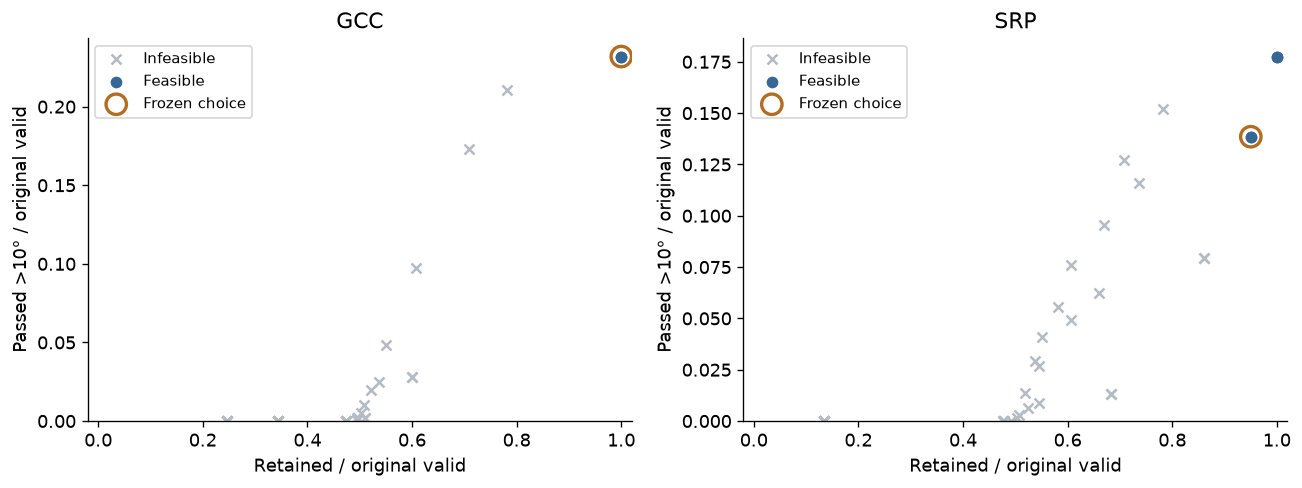

In [2]:
tradeoff = pd.DataFrame(_read_csv_gz(out / 'development_tradeoff.csv.gz'))
plt.rcParams.update({'font.size':11,'figure.dpi':120,'axes.spines.top':False,'axes.spines.right':False})
methods = ['all_6_equal_gcc_wls', 'equal_weight_srp_phat']
fig, axes = plt.subplots(1,2, figsize=(11,4.2))
for method, ax in zip(methods,axes):
    data = tradeoff[tradeoff.method == method]
    x = data.retention.astype(float); y = data.over_10_passed_all_valid.astype(float)
    feasible = data.feasible.eq('True')
    ax.scatter(x[~feasible], y[~feasible], c='#b4bbc3', marker='x', label='Infeasible')
    ax.scatter(x[feasible], y[feasible], c='#376795', marker='o', label='Feasible')
    t = review['feature_thresholds'][method]
    selected = data[(data.minimum_participation.astype(float)==t['minimum_participation']) & (data.minimum_margin.astype(float)==t['minimum_margin'])]
    ax.scatter(selected.retention.astype(float), selected.over_10_passed_all_valid.astype(float), facecolors='none',edgecolors='#b26d22',s=150,lw=2,label='Frozen choice')
    ax.set_title('GCC' if method==methods[0] else 'SRP')
    ax.set_xlabel('Retained / original valid'); ax.set_ylabel('Passed >10° / original valid')
    ax.set_xlim(-.02,1.02); ax.set_ylim(bottom=0); ax.legend(fontsize=9)
fig.tight_layout(); fig.savefig(out/'development_tradeoff.png',bbox_inches='tight'); plt.show()

## Evaluation: все кадры и исходные знаменатели
Сопоставление до/после gate на тех же raw оценках. Доли good false rejection условны на good ≤5°. Снижение conditional P95 само по себе не доказывает пригодность.

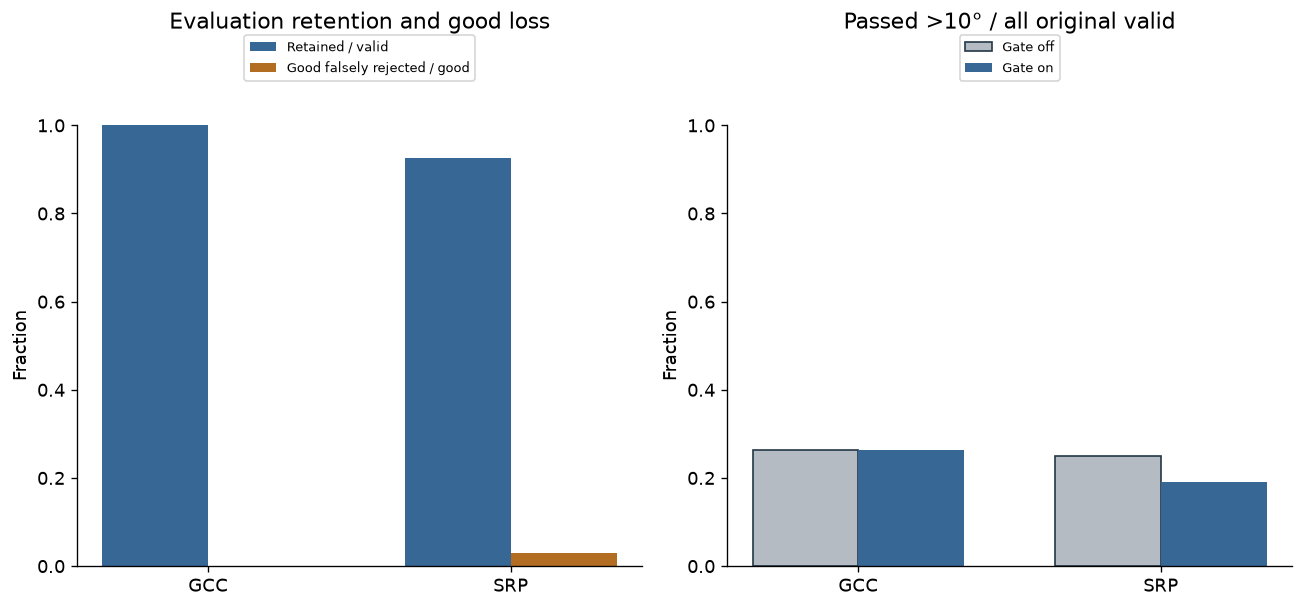

retention  \
method                source_class           distance_m gate              
all_6_equal_gcc_wls   broadband              200        off      1.0000   
                                                        on       1.0000   
                                             700        off      1.0000   
                                                        on       1.0000   
                      nonstationary_harmonic 200        off      1.0000   
                                                        on       1.0000   
                                             700        off      1.0000   
                                                        on       1.0000   
equal_weight_srp_phat broadband              200        off      1.0000   
                                                        on       1.0000   
                                             700        off      1.0000   
                                                        on       1.0000   
                      nonstationary_harmonic 200        off      1.0000   
                                                        on       0.9279   
                                             700        off      1.0000   
                                                        on       0.7784   

                                                              accepted_p95_deg  
method                source_class           distance_m gate                    
all_6_equal_gcc_wls   broadband              200        off             0.2476  
                                                        on              0.2476  
                                             700        off             0.9531  
                                                        on              0.9531  
                      nonstationary_harmonic 200        off            26.1072  
                                                        on             26.1072  
                                             700        off           115.5969  
                                                        on            115.5969  
equal_weight_srp_phat broadband              200        off             0.2472  
                                                        on              0.2472  
                                             700        off             0.9352  
                                                        on              0.9352  
                      nonstationary_harmonic 200        off            17.7486  
                                                        on             16.5575  
                                             700        off            97.2962  
                                                        on             89.9197

In [3]:
metrics = pd.DataFrame(_read_csv_gz(out/'bearing_metrics.csv.gz'))
ev = metrics[(metrics.split=='evaluation') & (metrics.subset=='all_frames')]
fig, axes = plt.subplots(1,2,figsize=(11,5.2))
labels=[]; retention=[]; rejected_good=[]; original_large=[]; passed_large=[]
for result in review['bearing']:
    labels.append('GCC' if result['method']==methods[0] else 'SRP')
    retention.append(result['retention']); rejected_good.append(result['good_false_rejection'])
    original_large.append(result['baseline_over_10_all_valid']);passed_large.append(result['gated_over_10_all_valid'])
x=np.arange(2); width=.35
axes[0].bar(x-width/2,retention,width,color='#376795',label='Retained / valid')
axes[0].bar(x+width/2,rejected_good,width,color='#b26d22',label='Good falsely rejected / good')
axes[1].bar(x-width/2,original_large,width,color='#b4bbc3',edgecolor='#243746',label='Gate off')
axes[1].bar(x+width/2,passed_large,width,color='#376795',label='Gate on')
for ax in axes: ax.set_xticks(x,labels);ax.set_ylim(0,1);ax.set_ylabel('Fraction');ax.legend(fontsize=8,loc='upper center',bbox_to_anchor=(.5,1.22))
axes[0].set_title('Evaluation retention and good loss',pad=58)
axes[1].set_title('Passed >10° / all original valid',pad=58)
fig.tight_layout();fig.savefig(out/'evaluation_tradeoff.png',bbox_inches='tight');plt.show()
ev.groupby(['method','source_class','distance_m','gate'])[['retention','accepted_p95_deg']].agg(lambda s: pd.to_numeric(s,errors='coerce').mean()).round(4)

### Доступность от станций в причинном trailing 3 s окне
Доставка учитывается до публикации: будущие события не входят в окно. Окна и кадры зависимы. Все кадры и tracker stride приведены отдельно.

In [4]:
windows = pd.DataFrame(_read_csv_gz(out/'station_availability.csv.gz'))
for key in ['trailing_3s_2_stations_fraction','trailing_3s_3_stations_fraction','instantaneous_3_stations_fraction']:
    windows[key] = pd.to_numeric(windows[key])
windows[windows.split=='evaluation'].groupby(['method','gate','subset'])[['trailing_3s_2_stations_fraction','trailing_3s_3_stations_fraction','instantaneous_3_stations_fraction']].mean().round(4)

trailing_3s_2_stations_fraction  \
method                gate subset                                            
all_6_equal_gcc_wls   off  all_frames                               0.9996   
                           tracker_stride                           0.9939   
                      on   all_frames                               0.9996   
                           tracker_stride                           0.9939   
equal_weight_srp_phat off  all_frames                               0.9996   
                           tracker_stride                           0.9939   
                      on   all_frames                               0.9996   
                           tracker_stride                           0.9932   

                                           trailing_3s_3_stations_fraction  \
method                gate subset                                            
all_6_equal_gcc_wls   off  all_frames                               0.9990   
                           tracker_stride                           0.9879   
                      on   all_frames                               0.9990   
                           tracker_stride                           0.9879   
equal_weight_srp_phat off  all_frames                               0.9990   
                           tracker_stride                           0.9879   
                      on   all_frames                               0.9989   
                           tracker_stride                           0.9848   

                                           instantaneous_3_stations_fraction  
method                gate subset                                             
all_6_equal_gcc_wls   off  all_frames                                 1.0000  
                           tracker_stride                             1.0000  
                      on   all_frames                                 1.0000  
                           tracker_stride                             1.0000  
equal_weight_srp_phat off  all_frames                                 1.0000  
                           tracker_stride                             1.0000  
                      on   all_frames                                 0.8209  
                           tracker_stride                             0.8136

## Tracking: заранее выбранные 200 m, replicate 0, оба класса
Только three-station confirmation; максимум 8 replay. Истина не входит в gate или трекер. Количество fits суммировано по всем поколениям.

In [5]:
tracks = pd.DataFrame(_read_csv_gz(out/'tracking_metrics.csv.gz'))
columns = ['source_class','method','gate','ever_confirmed','first_confirmation_time_s_relative','availability_fraction','position_rmse_m_conditional','position_p95_m_conditional','total_executed_optimizations']
tracks[columns]

,source_class,method,gate,ever_confirmed,first_confirmation_time_s_relative,availability_fraction,position_rmse_m_conditional,position_p95_m_conditional,total_executed_optimizations
0,broadband,all_6_equal_gcc_wls,off,True,1.0553125,0.9454545454545454,2.0063724874328828,3.8276114634531053,2
1,broadband,all_6_equal_gcc_wls,on,True,1.0553125,0.9454545454545454,2.0063724874328828,3.8276114634531053,2
2,broadband,equal_weight_srp_phat,off,True,1.0553125,0.9454545454545454,2.0004280273514965,3.8146653935056043,2
3,broadband,equal_weight_srp_phat,on,True,1.0553125,0.9454545454545454,2.0004280273514965,3.8146653935056043,2
4,nonstationary_harmonic,all_6_equal_gcc_wls,off,False,,0.0,,,128
5,nonstationary_harmonic,all_6_equal_gcc_wls,on,False,,0.0,,,128
6,nonstationary_harmonic,equal_weight_srp_phat,off,False,,0.0,,,128
7,nonstationary_harmonic,equal_weight_srp_phat,on,False,,0.0,,,128


### Ошибка координат и отсутствующие публикации
Пустые значения остаются NaN и разрывают линии. Таблица availability и off/on сравнение выше обязательны для интерпретации.

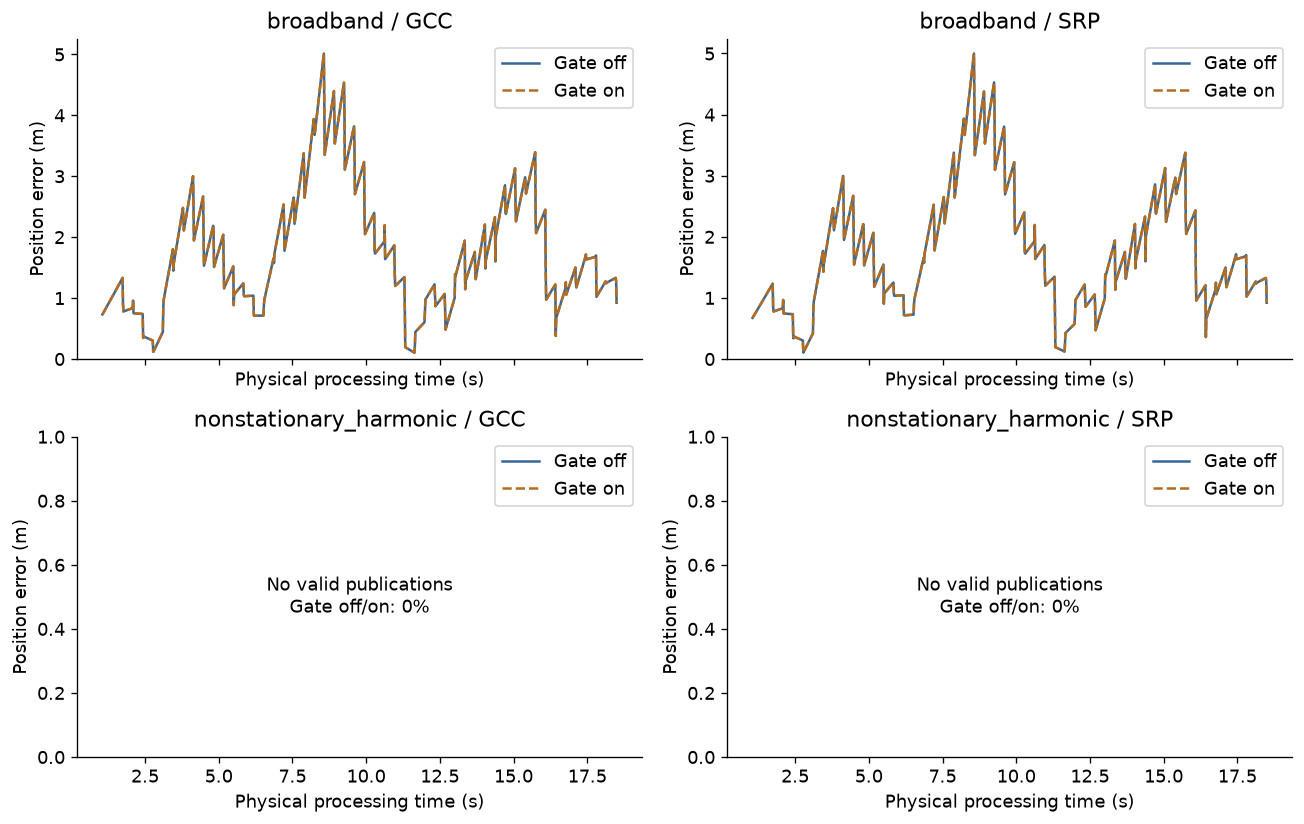

In [6]:
fig,axes=plt.subplots(2,2,figsize=(11,7),sharex=True)
for row,cls in enumerate(['broadband','nonstationary_harmonic']):
    index=8 if cls=='broadband' else 12
    for col,method in enumerate(methods):
        ax=axes[row,col]
        for mode,color,style in [('off','#376795','-'),('on','#b26d22','--')]:
            directory=out/'replays'/f'{index:02d}_{method}_{mode}'
            data=pd.DataFrame(_read_csv_gz(directory/f'tracking_{method}_three_station_confirmation.csv.gz'))
            t=pd.to_numeric(data.processing_time_s);error=pd.to_numeric(data.position_error_m,errors='coerce')
            ax.plot(t,error,color=color,linestyle=style,label=f'Gate {mode}')
        if cls=='nonstationary_harmonic':
            ax.text(.5,.5,'No valid publications\nGate off/on: 0%',ha='center',va='center',transform=ax.transAxes)
            ax.set_ylim(0,1)
        ax.set_title(cls+' / '+('GCC' if col==0 else 'SRP'));ax.set_ylabel('Position error (m)');ax.set_ylim(bottom=0);ax.legend()
        ax.set_xlabel('Physical processing time (s)')
fig.tight_layout();fig.savefig(out/'tracking_errors.png',bbox_inches='tight');plt.show()

### Сохранённые кривые и максимум: заранее выбранный harmonic frame 0
Это illustration текущего кадра, а не выбор характерного случая по truth. Кубическая SRP-карта использует прежние GCC curves; карта coarse 5° и не доказывает глобальную уникальность.

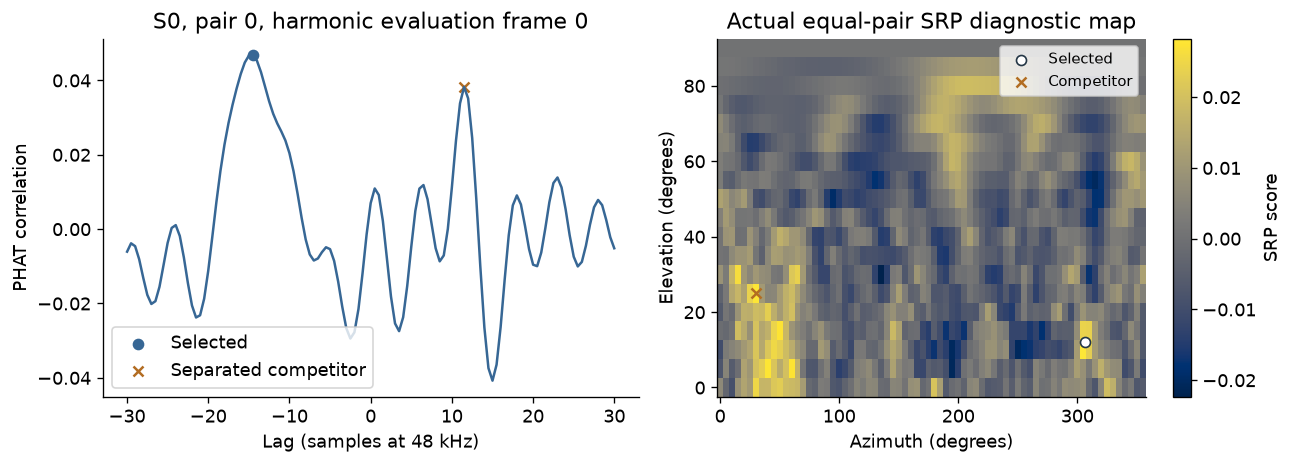

In [7]:
directory=out/'runs'/'12'
curve=np.load(directory/'curves_S0_0.npz',allow_pickle=False)
fig,axes=plt.subplots(1,2,figsize=(11,4))
i=0;lag=curve[f'lag_{i}'];corr=curve[f'correlation_{i}'];peak=int(curve['gcc_peak_indices'][i]);comp=int(curve['gcc_competitor_indices'][i])
axes[0].plot(lag,corr,color='#376795');axes[0].scatter(lag[peak],corr[peak],marker='o',color='#376795',label='Selected')
if comp>=0:axes[0].scatter(lag[comp],corr[comp],marker='x',color='#b26d22',label='Separated competitor')
axes[0].set_xlabel('Lag (samples at 48 kHz)');axes[0].set_ylabel('PHAT correlation');axes[0].set_title('S0, pair 0, harmonic evaluation frame 0');axes[0].legend()
image=axes[1].imshow(curve['srp_scores'].reshape(19,72),origin='lower',aspect='auto',extent=[-2.5,357.5,-2.5,92.5],cmap='cividis')
u=curve['srp_selected_direction'];phi=np.rad2deg(np.arctan2(u[1],u[0]))%360;el=np.rad2deg(np.arcsin(np.clip(u[2],-1,1)))
axes[1].scatter(phi,el,c='#ffffff',edgecolors='#243746',marker='o',label='Selected')
ci=int(curve['srp_competitor_index'])
if ci>=0:
    v=curve['srp_directions'][ci];axes[1].scatter(np.rad2deg(np.arctan2(v[1],v[0]))%360,np.rad2deg(np.arcsin(np.clip(v[2],-1,1))),c='#b26d22',marker='x',label='Competitor')
axes[1].legend(fontsize=9)
axes[1].set_xlabel('Azimuth (degrees)');axes[1].set_ylabel('Elevation (degrees)');axes[1].set_title('Actual equal-pair SRP diagnostic map');fig.colorbar(image,ax=axes[1],label='SRP score')
fig.tight_layout();fig.savefig(out/'peak_example.png',bbox_inches='tight');plt.show()

## Выводы

По этому synthetic transfer SRP margin частично отделяет крупные ошибки,
но относительное снижение 23,67% ниже замороженных 25%; GCC пороговому
отбору не помог. Tracking не улучшилось: broadband off/on одинаковы,
harmonic все четыре replay без подтверждения, с пределом 128 fits.

Поэтому joint criterion **не пройден**, gate остаётся default off.
Результат относится только к этим dependent synthetic cases: два реализации
и общие banks не дают независимых статистических испытаний. Нет настройки
R/Qc/filter/budgets по evaluation или утверждения о калиброванных вероятностях.

Отчёт: `BEARING_AMBIGUITY_RETRY_REPORT.md`. Старый отказ и notebook остаются
отдельно. Команды просмотра — `BEARING_AMBIGUITY_RUNBOOK.md`.